# Машинное обучение, ФКН ВШЭ

## Практическое домашнее задание 3.1 Базовая генерация признаков

### Общая информация

Дата выдачи: 23.02.2026

Мягкий дедлайн: 12.03.2026 23:59MSK

Жесткий дедлайн: 16.03.2026 23:59MSK

### О задании

В данном задании вы познакомитесь с базовыми подходами для создания новых признаков в табличном машинном обучении. Вам понадобится подумать над тем, зачем мы делаем те или иные преобразования, научиться принимать решения, дающие наилучшие результаты, и узнать, как реализовывать их при помощи библиотек

### Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за эту часть — 6 баллов. Детальнее про оценивание — в самом конце ноутбука.

Сдавать задание после указанного срока сдачи нельзя. При выставлении неполного балла за задание в связи с наличием ошибок на усмотрение проверяющего предусмотрена возможность исправить работу на указанных в ответном письме условиях.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке. Также оценка может быть снижена за плохо читаемый код и плохо считываемые диаграммы.

Все ответы должны сопровождаться кодом или комментариями о том, как они были получены.

### Формат сдачи
Задания сдаются через систему Anytask. Инвайт можно найти на странице курса. Присылать необходимо ноутбук с выполненным заданием. Сам ноутбук называйте в формате **homework-practice-03-base-Username.ipynb**, где Username — ваша фамилия.

### **Сетап**

<img style="float: right; padding-right:15px; padding-bottom:10px" src="https://i.postimg.cc/26KqqSb2/pomoika2.png" height=300px width=200px alt="Pomoika 2">
    
В этом домашнем задании мы будем работать с задачей классификации, но сконцентрируемся на том, что приносит не меньшую пользу, чем сами модели — замешиванию данных.

Целевая метрика уже выбрана за нас: мы будем считать $\text{ROC-AUC}$, но не простой, а коэффициент Джини:

$$ \text{Gini} = 2 \cdot \text{ROC-AUC} - 1$$

Конечная цель данного мероприятия — собрать пайплайн машинного обучения от и до, начиная с предобработки данных, заканчивая оптимизацией. При желании это можно доделать до целого пет-проекта, особенно если добавить сбор данных и деплой модели, но в дз этого не будет :(.

Цель конкретно базового ноутбука — познакомить вас с основными преобразованиями и собрать солидный фундамент для преобразований посложнее.

In [ ]:
from sklearn.metrics import roc_auc_score


def gini(y_true, y_score):
    return 2 * roc_auc_score(y_true, y_score) - 1.0

#### **Данные**

У вас на руках (на Kaggle) датасет по широко известной в неузких кругах видеоигре Dota 2, скачанный через OpenDota API и заботливо анонимизированный. Если вы не знакомы с игрой — ничего страшного, все необходимое для заданий в базовой части мы подробно опишем.

Нас интересует исход матча — победа или поражение, исходя из совершенно разных факторов (например, чтобы делать ставки на спорт, осуждаем?). Это информация о сессии, игроках, героях, и т д. **в первые 15 минут** после начала матча.

Краткая сводка об игре:

- Dota 2 — командная игра: 5 игроков за Свет (Radiant) против 5 за Тьму (Dire).
- Каждый игрок управляет уникальным героем со своим набором атрибутов и способностей.
- Цель — снести главную постройку на вражеской базе (в простонародье трон).
- В процессе матча игроки добывают золото и опыт, покупают предметы и убивают противников, чтобы стать сильнее.
- Ничьих не бывает, фиксированного таймера нет — матч длится до падения трона.

#### 📌 **Важнейшее замечание**

Предполагается, что у вас уже сложилось понимание:
- как крутить и вертеть данные, чтобы фиты делались твёрдо, трансформы ложились чётко, шейпы датафреймов стакались и нужные джойны джойнились;
- как рисовать читаемые графики;
- как проверять качество модели;

Пожалуйста, следите за этим очень-очень внимательно, иначе рискуете получить штраф и всеобщее порицание в нашем уютном МО-1 чатике (хотя, у этого есть плюсы).

Если возникнут вопросы по игровой части — **не стесняйтесь** спрашивать, гуглить, обращаться к GPT или, прости Господи, дотерам. Знание области — важнейшая составляющая хорошего фича инжиниринга

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Для лучшего понимания, в голубеньких пунктах будет небольшое <font color="#647cb8">**обоснование**</font> того, зачем вообще делается то или иное преобразование (в колабе придётся включать интуицию, там не работает HTML). Вы можете её скипнуть, если всё понятно и без этого

</div>

<div style="border-left: 5px solid #f68c9d; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

В пунктах с розоватой, как у всеми любимого Pudge, расцветкой мы попросим вас написать <font color="#f68c9d">**Ответ**</font> на <font color="#f68c9d">**Вопрос**</font> или <font color="#f68c9d">**рефлексию**</font>, которая должна направить вашу мысль о том, как варить фичи, в нужном направлении. Уметь аргументировать свою точку зрения важно не менее

Пожалуйста, даже если вы уже прожжённый дед инсайд и дата-сайентист 14 уо, всё равно <font color="#f68c9d">**порефлексируйте**</font>. Количество потерянных нервных клеток и ваш успех на соревновании напрямую зависят от базовой предобработки.
Вы **можете** писать <font color="#f68c9d">**её**</font> ёмко, но только если **знаете** ответ

</div>

<div style="border-left: 5px solid #cb9255; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(200, 156, 105, 0.05);">

<font>По ходу домашки вам придётся делать <font color="#cb9255">**выборы**</font> и подбирать <font color="#cb9255">**гиперпараметры**</font>. Какие-то из них важнее остальных. У ряда выборов последствия чисто номинальные, какие-то видоизменят другие задания, третьи полностью определят, как вы будете делать остальную домашку.

Принимайте решения мудро. Не привязывайтесь к ним слишком сильно, возможно, в процессе вам захочется пересмотреть ваши жизненные приоритеты. Пробуйте, экспериментируйте, фичи это самое творческое, что есть в машинном обучении

При желании, в конце обоих ноутбуков есть инструменты, которые, при остром желании и избытке свободного времени, могут тупо перебрать все выборы и найти самый оптимальный, но это опционально
</div>

### **Часть 1. Это, так сказать, база. (3.25 балла)** <img align="center" height=28 width=28 src="https://media.tenor.com/5vGX5VO-IxsAAAAi/arthas.gif">

В которой студент учится смотреть на фичи под правильным углом и готовить из сырых данных простые, но аппетитные факторы

#### **Задание 1.1. Датасет** (0.5 балла)

Чтобы начать работу с данными, эти данные сперва нужно [загрузить](https://www.kaggle.com/t/6fd940fbeb1746a78031e5d0277f6105). Пока что нам потребуются лишь:

1. Информация о матчах - `matches_df_train.csv`.
2. Тестовые данные для соревнования - `matches_df_test.csv`.

Посмотрите на все csv-файлы выше, создайте под каждый из них отдельный датафрейм и отметьте (текстом или кодом):
- объемы таблиц: как в Мб, так и `df.shape`
- какие в них есть колонки по своему содержанию

In [7]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )
import pandas as pd

train_df = pd.read_csv('matches_df_train.csv')
test_df = pd.read_csv('matches_df_test.csv')

print("Train shape:", train_df.shape)
train_df.info()
print("Test shape:", test_df.shape)
test_df.info()

target = train_df['radiant_win']

Train shape: (641090, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 641090 entries, 0 to 641089
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   match_id     641090 non-null  int64  
 1   date         641090 non-null  object 
 2   region       641090 non-null  object 
 3   game_mode    641090 non-null  int64  
 4   duration     641090 non-null  int64  
 5   radiant_win  641090 non-null  bool   
 6   avg_mmr      472334 non-null  float64
dtypes: bool(1), float64(1), int64(3), object(2)
memory usage: 30.0+ MB
Test shape: (59748, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59748 entries, 0 to 59747
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   match_id   59748 non-null  int64  
 1   date       59748 non-null  object 
 2   region     59748 non-null  object 
 3   game_mode  59748 non-null  int64  
 4   avg_mmr    44504 non-null  flo

Отдельно хочется посмотреть распределение целевой переменной, покажите его, пожалуйста

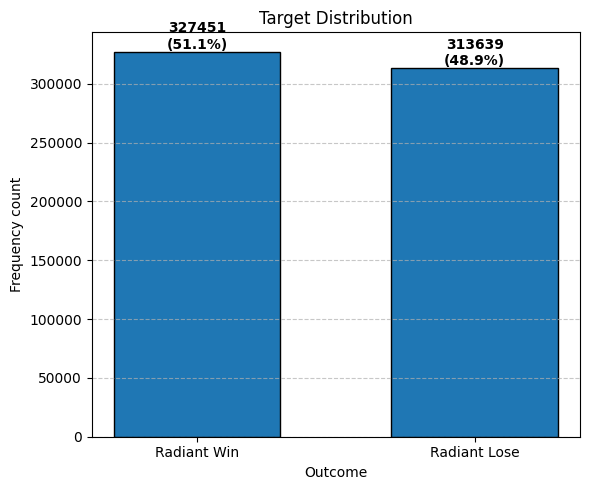

In [8]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )
import matplotlib.pyplot as plt


class_counts = train_df['radiant_win'].value_counts()
class_names = ['Radiant Win' if i == True else 'Radiant Lose' for i in class_counts.index]

fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(class_names, class_counts, edgecolor='black', width=0.6)

total = len(train_df)
for bar in bars:
  height = bar.get_height()
  percentage = (height / total) * 100
  ax.annotate(f'{height}\n({percentage:.1f}%)',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_title('Target Distribution')
ax.set_xlabel('Outcome')
ax.set_ylabel('Frequency count')
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

<div style="border-left: 5px solid #c27985; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** подходящая ли в данном случае метрика $\text{Gini}$ в сравнении, например, с $\text{AUC-PR}$?

**Ответ:**
</div> Да, подходящая. Классы хорошо сбаланисрованы.

#### **Задание 1.2. Категории** (0.75 балла)

Чтобы построить реально балдёжную модель, зачастую не получится просто написать фит предикт. О нет, это долгая и утомительная возня. А если нужно ещё и отчётики писать, то хоть <span style="color:grey"><font size="1">~~вешайся (осуждаем)~~ </font></span> увольняйся. Так и здесь. И того, что есть, уже хватит, чтобы продемонстрировать глубокую и тёмную сторону Dota Science.

В целом, данные уже содержат признаки, по которым что-то даже можно построить, в частности — регионы.

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

У Radiant, по сравнению с Dire, исторически есть небольшое преимущество — чуть удобнее карта, порядок выбора героев и всё такое. В разных регионах бывают разные предпочтения по стилям игры и тактикам, и где-то это преимущество реализуют лучше

</div>

Посмотрите, где у нас содержится информация о регионе, на серверах которого был проведён матч, и постройте 2 графика:
1) Распределение регионов (процентное и абсолютное) на тренировочных и тестовых данных
2) Среднее значение таргета на трейне, в зависимости от региона

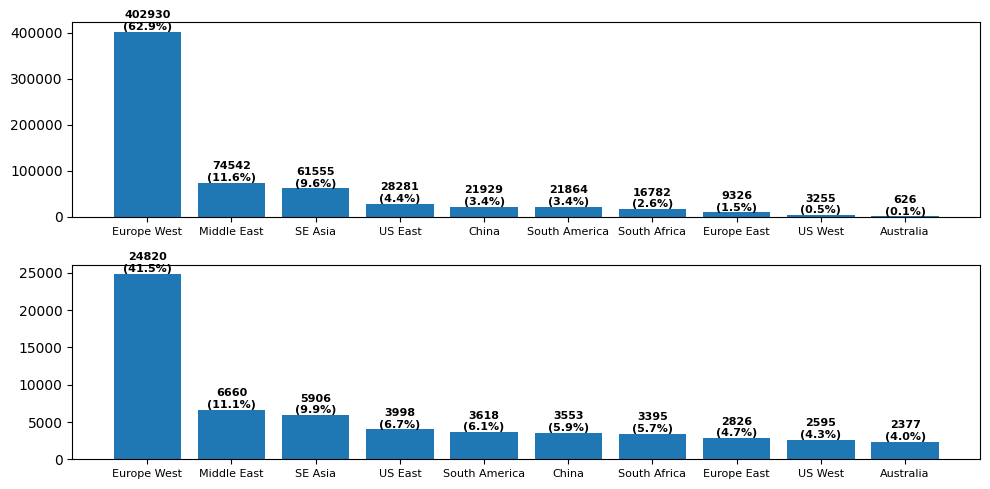

TOTAL PERCENTAGE: 100.00000000000001


In [9]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )
region_counts_train = train_df['region'].value_counts()
region_names_train = region_counts_train.index.astype(str)
region_counts_test = test_df['region'].value_counts()
region_names_test = region_counts_test.index.astype(str)

fig, ax = plt.subplots(2, 1, figsize=(10, 5))
bars = ax[0].bar(region_names_train, region_counts_train)

total = len(train_df)
total_percentage = 0
for bar in bars:
  height = bar.get_height()
  percentage = (height / total) * 100
  ax[0].annotate(f'{height}\n({percentage:.1f}%)',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                ha='center', va='bottom', fontsize=8, fontweight='bold')
  total_percentage += percentage


bars = ax[1].bar(region_names_test, region_counts_test)

total = len(test_df)
for bar in bars:
  height = bar.get_height()
  percentage = (height / total) * 100
  ax[1].annotate(f'{height}\n({percentage:.1f}%)',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                ha='center', va='bottom', fontsize=8, fontweight='bold')


ax[0].tick_params(axis='x', labelsize=8)
ax[1].tick_params(axis='x', labelsize=8)

plt.tight_layout()
plt.show()

print('TOTAL PERCENTAGE:', total_percentage)

In [10]:
region_target_mean = (train_df.groupby('region')['radiant_win']
  .mean()
  .sort_values(ascending=False)
  .reset_index()
)

region_target_mean

,region,radiant_win
0,Europe East,0.577204
1,Europe West,0.534574
2,Australia,0.533546
3,China,0.510876
4,SE Asia,0.501893
5,South Africa,0.490883
6,South America,0.483214
7,Middle East,0.436854
8,US East,0.413281
9,US West,0.364363


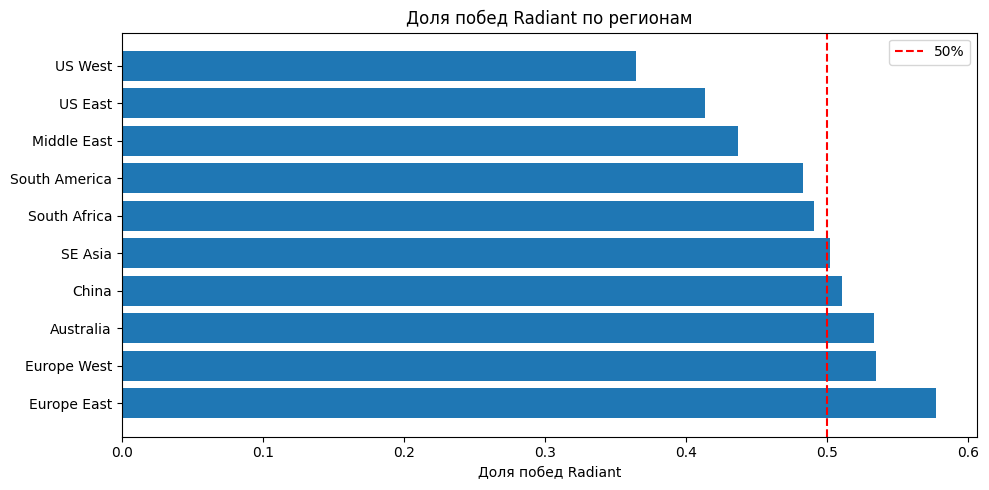

In [27]:
plt.figure(figsize=(10, 5))
plt.barh(
    region_target_mean['region'],
    region_target_mean['radiant_win']
)

plt.axvline(0.5, color='red', linestyle='--', label='50%')
plt.title('Доля побед Radiant по регионам')
plt.xlabel('Доля побед Radiant')
plt.legend()

plt.tight_layout()
plt.show()

<div style="border-left: 5px solid #c27985; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** что вы можете сказать о распределении регионов? Объясните, получится ли вообще обучить по нему модель, есть ли там сигнал?

**Ответ:**  
Есть некая связь между таргетом и регионами. Например, в Европе Свет побеждает значительно чаще чем в Америке.  
В целом видна закономерность: Европа -> Азия -> Африка/Средневосток -> Америка

Наша первая развилка — <font color="#cb9255">**выбор**</font>, какой из энкодеров стащить. Рекомендуется брать что-то из `category_encoders`, они похожи на стандартные из `sklearn`, но их больше и применять их проще.

| <font color="#cb9255">**One-Hot Encoder**</font> | <font color="#cb9255">**Target Encoder**</font> |
| :--- | :--- |
| Превращает категориальный признак в вектор из 0 и 1.  <br> 1 стоит на месте i‑го индекса, если у объекта есть i‑е значение признака. | Кодирует категориальный признак средним значением таргета.  <br> Среднее считается по всем объектам с i‑м значением признака. |

Можно взять и другой, но морально готовьтесь получить $\text{Gini} = 0$
</div>

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Без энкодинга использовать категориальные признаки в линейных моделях, увы, нельзя, выбор без выбора

</div>

In [12]:
!pip install -qU category-encoders

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.9/107.9 kB 8.9 MB/s eta 0:00:00


<div style="border-left: 5px solid #c27985; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** какой из энкодеров кажется вам наиболее привлекательным? Почему?

**Ответ:**
Можно взять One-Hot Encoder потому что кардинальность признака 'region' маленькая.

Закодируйте колонку `region` выбранным вами способом

In [13]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )
import category_encoders as ce

region_ohe = ce.OneHotEncoder(cols=['region'])
region_ohe.fit(train_df, target)

X_train = region_ohe.transform(train_df)

X_train.head()

,match_id,date,region_1,region_2,region_3,region_4,region_5,region_6,region_7,region_8,region_9,region_10,game_mode,duration,radiant_win,avg_mmr
0,1,2024-02-12,1,0,0,0,0,0,0,0,0,0,4,2625,False,3519.7
1,2,2024-04-08,0,1,0,0,0,0,0,0,0,0,2,7526,True,2330.9
2,3,2024-06-16,0,0,1,0,0,0,0,0,0,0,1,2831,True,1579.6
3,4,2024-09-16,0,0,0,1,0,0,0,0,0,0,22,1438,False,NaN
4,5,2024-03-31,0,1,0,0,0,0,0,0,0,0,22,2051,True,NaN


#### **Задание 1.3. Даты** (1.25 балла)

Если нам хочется видеть будущее, именно время диктует, что брать можно, а что никак нельзя

Найдите колонку дат на тренировочных данных и:
1. Постройте график доли побед Radiant в зависимости от даты матча
2. Сравните временные диапазоны на трейне и тесте

Диапазон дат на train: 2024-01-01 - 2024-11-30

Диапазон дат на test: 2024-12-01 - 2024-12-31



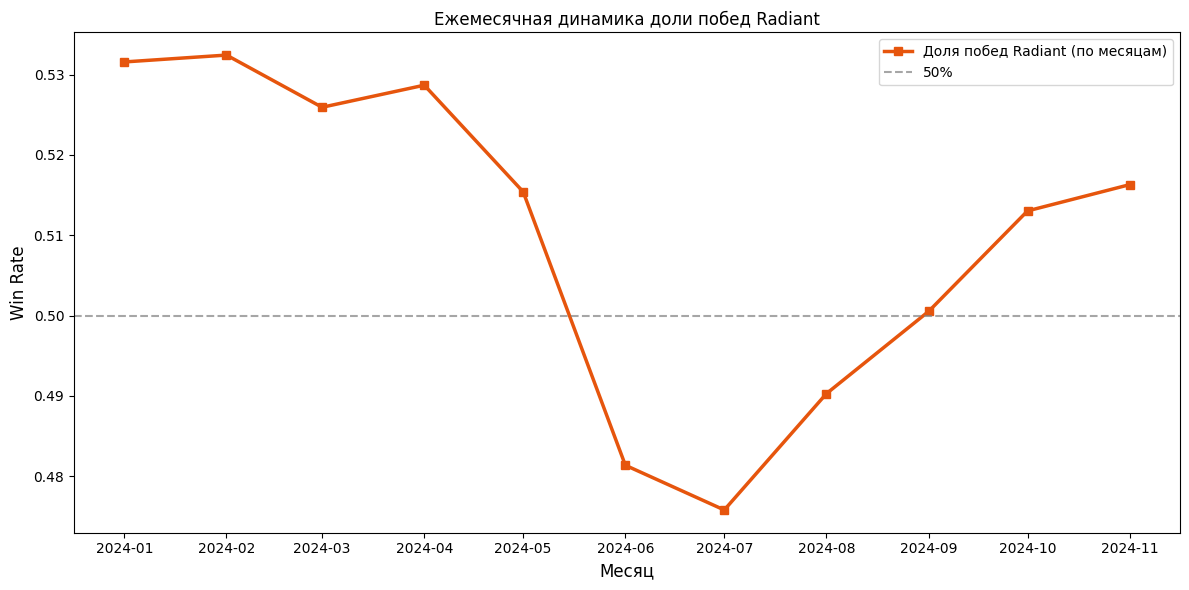

In [14]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )
print(f"Диапазон дат на train: {X_train['date'].min()} - {X_train['date'].max()}\n")
# На train у нас одинадцать месяцев (2024 Янв - 2024 Ноябрь), можно смотреть по месяцам
print(f"Диапазон дат на test: {test_df['date'].min()} - {test_df['date'].max()}\n")
# На test: 2024 1 Дек - 2024 31 Дек
# То есть test и train уже разделены хронологически, и в train нет протечки будущего

X_train['date'] = pd.to_datetime(X_train['date'])
X_train['match_month'] = X_train['date'].dt.to_period('M').dt.to_timestamp()

monthly_winrate = (
    X_train.groupby('match_month')['radiant_win'].mean().reset_index()
)

plt.figure(figsize=(12, 6))
plt.plot(
    monthly_winrate['match_month'],
    monthly_winrate['radiant_win'],
    marker='s',
    linestyle='-',
    color='#e6550d',
    linewidth=2.5,
    label='Доля побед Radiant (по месяцам)'
)

plt.axhline(y=0.5, color='gray', linestyle='--', alpha=0.7, label='50%')
plt.title('Ежемесячная динамика доли побед Radiant')
plt.xlabel('Месяц', fontsize=12)
plt.ylabel('Win Rate', fontsize=12)

plt.legend()
plt.tight_layout()
plt.show()

<div style="border-left: 5px solid #c27985; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** видите ли вы какой-то паттерн в распределении дат? Можете ли вы объяснить при помощи сети Интернет, что там произошло? \
(Подсказка: соревновательные игры периодически обновляются)

**Ответ:**

</div>

Теперь давайте что-нибудь повыделяем.

<div style="border-left: 5px solid #5584a8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Даты сами по себе это всегда очень простые фичи, функционал есть в любой библиотеке. Связь с таргетом может быть, но не обязана. Именно даты проверить легко и быстро, зависимости бывают неожиданными. Впрочем, это не единственная причина, не переключайтесь

</div>

С таймстемпом можно делать не так много, кроме базовых манипуляций:

1. Вытащите лежащую на поверхности информацию, например, день и день недели. Хватит и этих двух
2. Посмотрите сами на список возможных признаков, будь то [pandas](https://pandas.pydata.org/docs/user_guide/timeseries.html#time-date-components) или [polars](https://docs.pola.rs/api/python/stable/reference/expressions/temporal.html), и <font color="#cb9255">**либо добавьте**</font> 2 признака, которые, как вам кажется, сработают, <font color="#cb9255">**либо поясните**</font>, почему это ничего не даст

<div style="border-left: 5px solid #c27985; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** необходимо ли кодировать признаки из дат? Если да, то какие и как? Если нет, то почему? </font>

**Ответ:**

</div>

3. Закодируйте новые признаки, согласно вашему ответу

In [28]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )
X_train['match_day'] = X_train['date'].dt.day
X_train['day_of_week'] = X_train['date'].dt.dayofweek
X_train['month'] = X_train['date'].dt.month
X_train['is_weekend'] = (X_train['day_of_week'] >= 5).astype(int)


Кажется, мы что-то забыли... Ах да, надо бы и модель обучить, вот только без валидации это будет как-то не по-моповски, надо озаботиться этим вопросом.

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

На самом деле временная структура нужна не столь, чтобы вытащить какие-то признаки, сколько, чтобы понять распределение и изменение данных во времени же. Даты играют в этом прямую роль

</div>

<div style="border-left: 5px solid #c27985; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** почему здесь будет не лучшим решением брать случайное разбиение на трейн и валидацию?

**Ответ:**

Потому что тогда в валидацию могут попасть семплы из будущего, а тренировочные данные будут содержать события после валидационных. Такое на настоящем инференсе и моменте предсказаная невозможно, поэтому это неправильный вариант, хоть и бывают случаи когда может и не улучшить качество искусственно.

Тут выбор у вас решили отобрать, делать мы будем OOT валидацию. Впрочем, какие-то опции ещё остались

<table width="800" border="1" cellpadding="8" cellspacing="0">
  <tr>
    <th width="50%">
      <font color="#cb9255">OOT (Out-of-Time)</font>
    </th>
    <th width="50%">
      <font color="#cb9255">CV OOT (Cross-Validation Out-of-Time)</font>
    </th>
  </tr>
  <tr>
    <td valign="top">
      Валидация с одной отложенной подвыборкой, <br>
      взятой после трешхолда t. Простая, как палка, <br>
      но если валидация получится грустной — <br>
      аномальной, нетипичной, маленькой, — <br>
      то и метрика ваша тоже будет грустной.
    </td>
    <td valign="top">
      Кросс-валидация с k разбиениями по времени <br>
      с итеративным расширением исходного фолда. <br>
      Оценка метрики сместится куда меньше <br>
      по сравнению с плохим сплитом OOT, <br>
      но это долго, если фолдов много.
    </td>
  </tr>
  <tr>
    <td valign="top">
      <code>sklearn.model_selection.train_test_split</code>
    </td>
    <td valign="top">
      <code>sklearn.model_selection.TimeSeriesSplit</code>
    </td>
  </tr>
</table>



Настройте любой из видов валидации (<font color="#cb9255">**трешхолд**</font> `t` или <font color="#cb9255">**число фолдов**</font> <code>n_folds</code></font> подберите сами). Они оба должны показывать качество адекватно, хотя второй теоретически должен быть более обоснован. CV-OOT не даст вам бонусов, но кто знает, за какие крохи Джини придётся бороться на соревновании?

In [29]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )
import numpy as np

dates = pd.to_datetime(train_df['date'])
cutoff = pd.Timestamp('2024-11-01')

train_mask = dates < cutoff
valid_mask = dates >= cutoff

y = train_df['radiant_win'].astype(int)
y_train = y.loc[train_mask]
y_val = y.loc[valid_mask]

print('Train:', train_mask.sum())
print('Validation:', valid_mask.sum())
print('Train идет до:', dates[train_mask].max())
print('Validation начинается с:', dates[valid_mask].min())

Train: 582297
Validation: 58793
Train идет до: 2024-10-31 00:00:00
Validation начинается с: 2024-11-01 00:00:00


И вот теперь мы уже наконец-то будем что-то обучать. Моделей классификации мы знаем как минимум две — SVM и логистическую регрессию, но есть нюанс.

Выборы, выборы..:

<table width="800" border="1" cellpadding="8" cellspacing="0">
  <tr>
    <th width="50%">
      <font color="#cb9255">Dedicated model</font>
    </th>
    <th width="50%">
      <font color="#cb9255">Gradient Descent</font>
    </th>
  </tr>
  <tr>
    <td valign="top">
      Большой разницы между <code>LogisticRegression</code> и <code>LinearSVC</code> <br>
      из <code>sklearn.linear_model</code> на самом деле нет: <br>
      разделяющие поверхности очень похожи, <br>
      оба хорошо оптимизированы специальными солверами.
    </td>
    <td valign="top">
      Градиентный спуск через <code>sklearn.linear_model.SGDClassifier</code> <br>
      с параметрами <code>loss="log_loss"</code> или <code>loss="hinge"</code> — <br>
      очень соблазнительная альтернатива, но!
    </td>
  </tr>
  <tr>
    <td valign="top">
      <font color="#cb9255"><b>+</b></font> Обучать и применять их в разы проще, <br>
      фит–предикт делает брр. <br>
      <font color="#cb9255"><b>−</b></font> Они используют сразу всю выборку <br>
      для обучения, а в ходе задания наша выборка <br>
      может вырасти раз так в 1000, немало!
    </td>
    <td valign="top">
      <font color="#cb9255"><b>+</b></font> Влезет любой датасет. <br>
      <font color="#cb9255"><b>+</b></font> Бóльший контроль над процессом обучения. <br>
      <font color="#cb9255"><b>−</b></font> Обучать на больших данных <br>
      (скорее про часть <b>advanced</b>) придётся через <code>partial_fit</code>, неудобно. <br>
      <font color="#cb9255"><b>−</b></font> Нужно подбирать больше гиперпараметров.
    </td>
  </tr>
</table>


Выберите <font color="#cb9255">**одну из**</font> моделей выше (хотя `LinearRegression` <font color="#cb9255">**тоже можно**</font>, если у вас сегодня авантюрное настроение, успех не гарантирован, о рисках узнаете на лекции) **(обращаем внимание, что другие варианты запрещены)**. Обучите по одному экземпляру на группах признаков:

- дат
- регионов
- дат и регионов

Ну и замерьте качество!

<font color="#cb9255">**NB**</font>:

1. Вы сразу можете строить роскошный пайплайн обучения, а не делать по кускам в отдельных блоках, про это есть **advanced** пункт (**6.1**) на 0.5 баллов
2. Если у вас есть GPU, то почему бы его и не [использовать](https://docs.rapids.ai/api/cuml/stable/)? Если гпу у вас нет, у вас теперь точно есть Kaggle, который щедро дарит 30 часов гпу в неделю, пользуйтесь на здоровье, за это есть маленький, но приятный буст на 0.25 балла (**пункт 6.3**)
3. Наконец, если вы сразу оформите хранилище для результатов запусков ваших моделей, вы снова получите 0.25 балла (**пункт 6.2**)

In [37]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

def make_features(df):
  date = pd.to_datetime(df['date'])
  mmr = df['avg_mmr'].clip(lower=0)

  return pd.DataFrame({
      'region': df['region'].fillna('unknown'),
      'match_day': date.dt.day,
      'day_of_week': date.dt.dayofweek,
      'month': date.dt.month,
      'is_weekend': (date.dt.dayofweek >= 5).astype(int),
      'mmr_missing': mmr.isna().astype(int),
      'mmr_raw': mmr,
      'mmr_log': np.log1p(mmr)
  }, index=df.index)


features = make_features(train_df)
test_features = make_features(test_df)

date_cols = ['match_day', 'day_of_week', 'month', 'is_weekend']
region_cols = ['region']


def make_preprocessor(columns):
  transformers = []

  if 'region' in columns:
    transformers.append((
        'region', OneHotEncoder(handle_unknown='ignore'),
        ['region']
    ))

  if 'day_of_week' in columns:
      transformers.append((
          'weekday',
          OneHotEncoder(handle_unknown='ignore'),
          ['day_of_week']
      ))

  numeric_cols = [
      c for c in columns
      if c not in ('region', 'day_of_week')
  ]

  if numeric_cols:
    transformers.append((
        'numeric', make_pipeline(
            SimpleImputer(strategy='median'),
            StandardScaler()
        ),
        numeric_cols
    ))

  return ColumnTransformer(
      transformers,
      sparse_threshold=1.0
  )


In [45]:
def evaluate(columns):
  preprocessor = make_preprocessor(columns)

  X_tr = preprocessor.fit_transform(
      features.loc[train_mask, columns]
  )
  X_val = preprocessor.transform(
      features.loc[valid_mask, columns]
  )

  model = LogisticRegression(
      solver='liblinear',
      C=1.0,
      max_iter=500,
      random_state=42,
  )

  model.fit(X_tr, y_train)

  train_score = gini(y_train, model.predict_proba(X_tr)[:, 1])
  valid_score = gini(y_val, model.predict_proba(X_val)[:, 1])

  return {
      'columns': columns,
      'train': train_score,
      'valid': valid_score,
  }

experiments = {
    'dates': date_cols,
    'regions': region_cols,
    'dates + regions': date_cols + region_cols,
}

results = {
    name: evaluate(cols)
    for name, cols in experiments.items()
}

pd.DataFrame(results).T[['train', 'valid']]

,train,valid
dates,0.032792,0.002588
regions,0.075624,0.076008
dates + regions,0.09007,0.077563


<div style="border-left: 5px solid #c27985; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** помогли ли даты? А должны? Хотите ли вы их оставить?

**Ответ:**

На train даты помогли значительно сильнее, чем на valid. На valid улучшение есть, но оно небольшое, и вопрос стоит ли оставлять даты зависит от того, нужен ли нам максимальное качество модели или ее размер и скорость обучения/инференса.

#### **Задание 1.4. Числа** (0.75 балла)

Остался неотвеченным лишь один вопрос — а что числовые признаки? С ними всё одновременно и проще, и сложнее.

Найдите, где хранится средний ммр матча — это средний рейтинг игроков, которые в нём участвовали, чем выше, тем лучше.

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

От ммра напрямую зависит то, как игроки пользуются естественным преимуществом Radiant. Чем игроки сильнее, тем чаще это должно происходить, в теории

</div>

Сделайте (на трейне, валидации и тесте) вот что :
1. Постройте график распределения ммров
2. Сравните, насколько распределения похожи между собой визуально

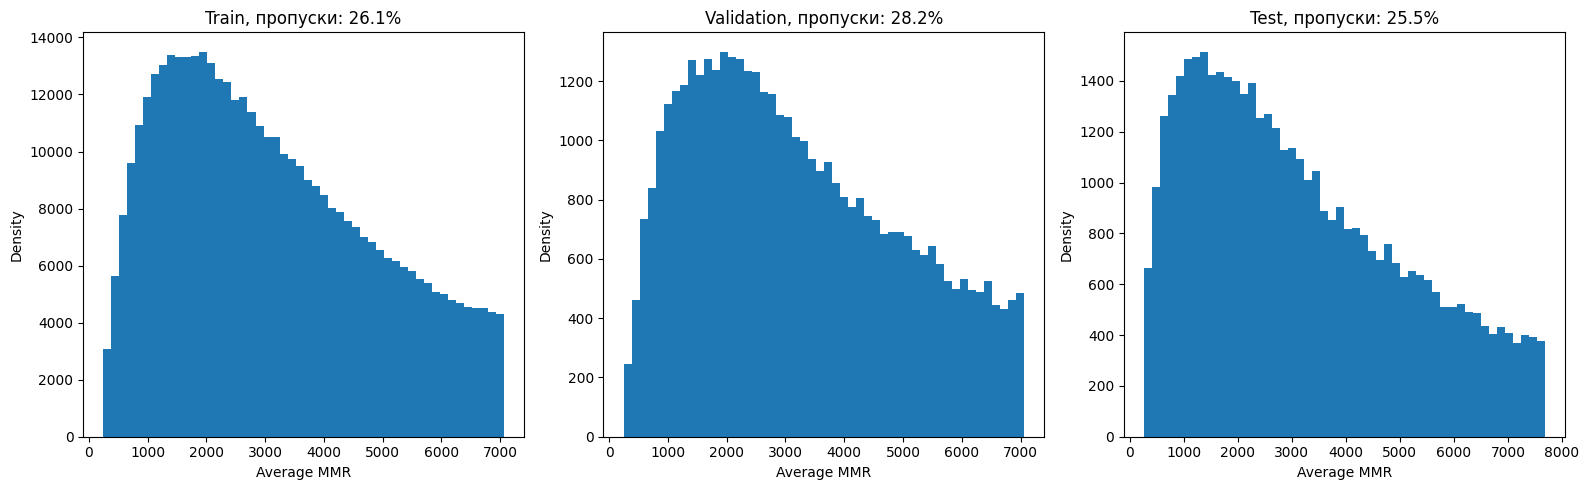

In [47]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )
splits = {
    'Train': train_df.loc[train_mask],
    'Validation': train_df.loc[valid_mask],
    'Test': test_df
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, df) in zip(axes, splits.items()):
  mmr = df['avg_mmr'].dropna()

  ax.hist(mmr, bins=50)
  ax.set_title(f'{name}, пропуски: {df['avg_mmr'].isna().mean():.1%}')
  ax.set_xlabel('Average MMR')
  ax.set_ylabel('Density')

plt.tight_layout()
plt.show()

<div style="border-left: 5px solid #c27985; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** как бы вы описали это распределение в целом, похоже ли оно на что-то знакомое вам?

**Ответ:**

Распределения похожи между и собой, и визуально выглядят как правосторонне-ассиметричное нормальное распределение.

Кто-то где-то говорил, что числовые признаки надо бы стандартизировать, чтобы вышло что-то годное. Этот кто-то прав, но как известно, практика — критерий истины

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Но в действительности это зависит от данных. Сходимость итеративных алгоритмов улучшается, но может пострадать качество, особенно, если распределение не нормальное, или есть отличие в $\mu$ и $\sigma$ на тесте

Однако даже пара пунктов Джини это довольно хороший буст, вы убедитесь, когда приступите к сореве, за них нужно бороться любой ценой, тем более, что это почти бесплатно

</div>

Так или иначе, у нас и распределение то не нормальное, но, к счастью, это решаемо. Сделайте такие преобразования признака ммров $f_{\text{mmr}}$ и нарисуйте их график:

$$f_{\text{mmr}} \mapsto \log( 1+f_{\text{mmr}} ); \qquad f_{\text{mmr}} \mapsto \sqrt{f_{\text{mmr}}}; \qquad f_{\text{mmr}} \mapsto \frac{1}{1+f_{\text{mmr}}}; \qquad f_{\text{mmr}} \mapsto \exp{\log f_{\text{mmr}}};$$

Затем выберите то, что вам нравится больше всего

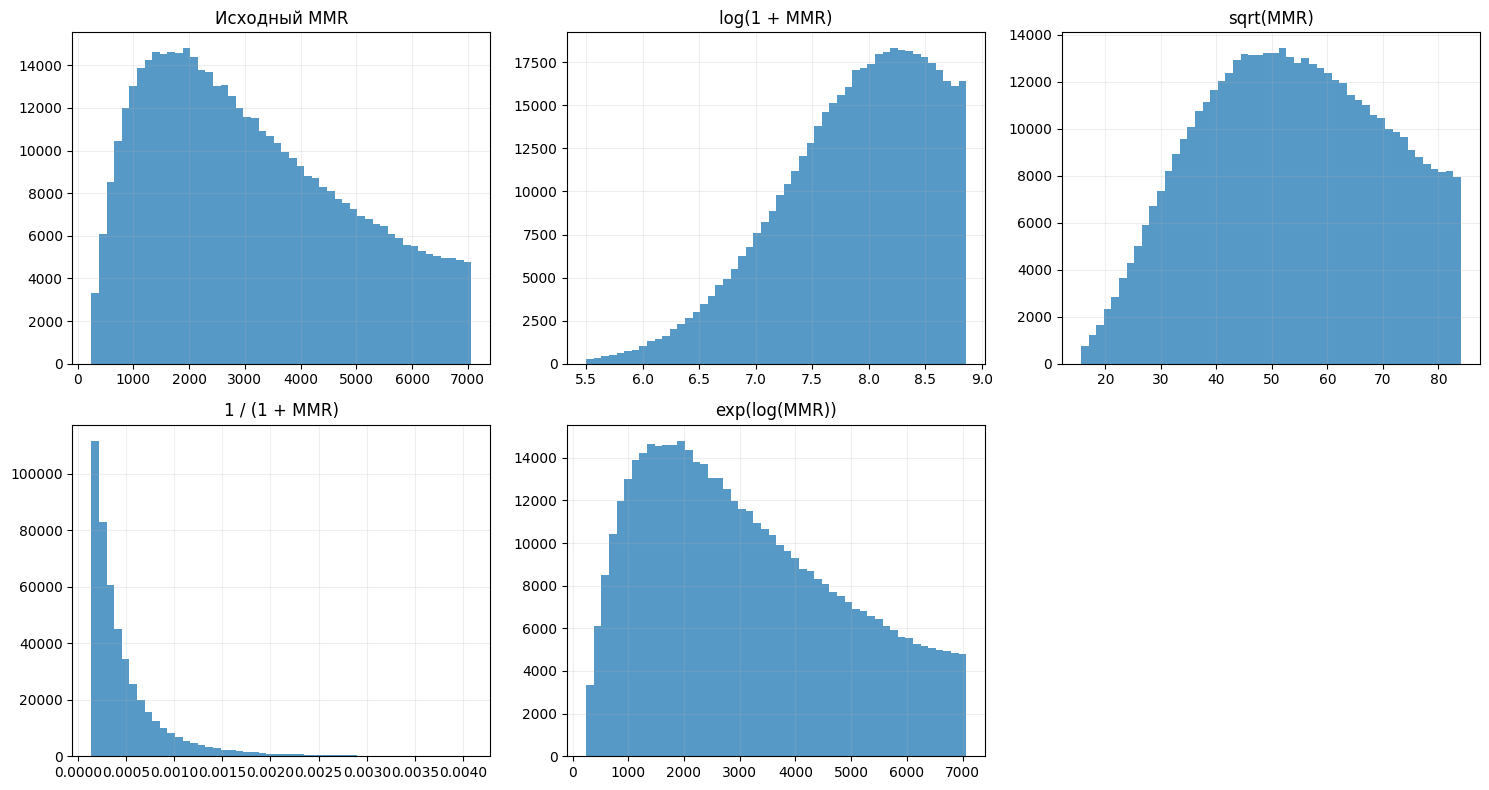

In [50]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )
mmr = train_df['avg_mmr'].dropna().clip(lower=0)

mmr_transforms = {
    'Исходный MMR': mmr,
    'log(1 + MMR)': np.log1p(mmr),
    'sqrt(MMR)': np.sqrt(mmr),
    '1 / (1 + MMR)': 1 / (1 + mmr),
    'exp(log(MMR))': np.exp(np.log(mmr[mmr > 0]))
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, (name, values) in zip(axes.flat, mmr_transforms.items()):
  ax.hist(values, bins=50, alpha=0.75)
  ax.set_title(name)
  ax.grid(alpha=0.2)

axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

Мы как-то раньше не обращали внимание, но шестое чувство подсказывает, что в ммрах есть пропуски. Выкинуть их не получится, потому что на тесте они тоже есть, поэтому выход один — чем-то заполнять.

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

А пропуски у нас есть, потому что не все игры рейтинговые, там информацию по ммру собрать не удастся

В категориальных признаках пропуски не так важны для линрега, их можно закодировать специальной категорией. В числовых проигнорировать их не получится

В любом случае, лучше дополнительно добавить признак-флаг `mmr_missing`, который говорит, что пропуск там на самом деле есть. <font color="#cb9255">**Можете**</font> замерить его влияние, если есть желание, вдруг мы советуем полную дичь и там Джини 0.9?

</div>

<div style="border-left: 5px solid #c27985; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** нормально ли в данном случае заполнить пропуски нулём? А чем тогда, если нет?

**Ответ:**

</div>

Момент истины. Обучите две новые модели: к оптимальному набору фичей из предыдущего пункта добавьте в одном случае фичу без преобразования, а в другом — после преобразования. Зацените эффект на трейне и на валидации

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Помните, что как бы ни было прекрасно и информативно преобразование в вашей голове, ключевое это перформанс на отложенной выборке \
В жизни каждого дата-сайентиста бывает такое, что фича, которая ну должна быть клёвой, <i>математически</i>, на практике оказывается той ещё жижей, и такое, увы, тоже нужно отслеживать

</div>

In [52]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )
best_name = max(results, key=lambda name: results[name]['valid'])
base_cols = results[best_name]['columns']

mmr_experiments = {
    'baseline': base_cols,
    'raw MMR': base_cols + ['mmr_raw', 'mmr_missing'],
    'log MMR': base_cols + ['mmr_log', 'mmr_missing'],
}

mmr_results = {
    name: evaluate(cols)
    for name, cols in mmr_experiments.items()
}

pd.DataFrame(mmr_results).T[['train', 'valid']]

,train,valid
baseline,0.09007,0.077563
raw MMR,0.150112,0.146082
log MMR,0.151831,0.147182


### **Часть 2. Векторы** (1.5 балла) <img align="center" height=28 width=28 src="https://static.wikia.nocookie.net/dota2_gamepedia/images/1/17/Emoticon_sick.gif/revision/latest?cb=20180504011850">

В которой студент испытывает вьетнамские флешбеки от дз1, фиксит чужие баги и делает нереально мощную фичу, которую можно полировать до посинения

#### **Задание 2.1. Большая чистка** (0.75 балла)

Пока что мы никак не использовали информацию про героев, а ведь от них напрямую зависит исход матча, их больше 100 штук и все они разные: кто-то сильнее, кто-то слабее, а кто-то красивее :3. Только в данные кто-то нагадил, придётся убирать! Тут придётся ещё разочек освежить `pandas`/`polars`

Датасеты, которые нас интересуют теперь — `player_df.csv` и `Constants.Heroes.csv`. Там есть и данные на трейне, и на тесте, мы их обязательно приджойним, но потом.

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Данные, как и стойло, необходимо чистить. Ранее нам везло и в целом каких-то извращений мы не наблюдали, да и тут сходу не увидим. Т.н. *"выбросы"* это, во-первых, тема отдельного холивара, а во-вторых история про доменное несоответствие, матстат такое не найдёт, но на то у нас есть мозг, верно?

Под доменом имеется в виду контекст, в котором создаются ваши данные, и процессы которого ваши данные описывают (в нашем случае — то, как устроена игра и баланс в ней). Тогда выброс — это то, что в контекст не вписывается, даже если ошибки там нет. Про это весь пункт

</div>

Первое, что нужно отсмотреть - главные ключи. Начнём с игроков. Повертите `account_id`, вас должны смутить как минимум два айдишника.

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Не все игроки делают свой профиль публичным, их айди в таком случае будет анонимизирован

Небольшая часть данных собрана некорректно, айди таких игроков тоже помечен особенным значением

</div>

In [97]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )
players_raw = pd.read_csv('player_df.csv')
heroes_df = pd.read_csv('Constants.Heroes.csv')

print('Players:', players_raw.shape)
print('Heroes:', heroes_df.shape)

display(players_raw.sample(3))
display(heroes_df.sample(3))

print(players_raw['account_id'].value_counts(dropna=False).head(15))
print('Missing account_id:', players_raw['account_id'].isna().sum())

Players: (7650825, 14)
Heroes: (126, 34)


,player_slot,account_id,hero_id,kills,deaths,assists,gold,last_hits,denies,gold_per_min,xp_per_min,hero_damage,tower_damage,match_id
3261360,130,85092030,50,0.0,7.0,5.0,63.0,42.0,6.0,196.0,221.0,1142.0,0.0,367072
1944956,4,4294967295,30,2.0,11.0,11.0,271.0,22.0,8.0,166.0,195.0,3725.0,47.0,188884
2253628,132,4294967295,14,12.0,7.0,24.0,2101.0,97.0,1.0,393.0,557.0,19098.0,1031.0,746453


,Unnamed: 0,id,name,primary_attr,attack_type,roles,img,icon,base_health,base_health_regen,...,attack_rate,base_attack_time,attack_point,move_speed,turn_rate,cm_enabled,legs,day_vision,night_vision,localized_name
101,101,103,npc_dota_hero_elder_titan,str,Melee,"['Initiator', 'Disabler', 'Nuker', 'Durable']",/apps/dota2/images/dota_react/heroes/elder_tit...,/apps/dota2/images/dota_react/heroes/icons/eld...,120,0.75,...,1.7,100,0.35,310,NaN,True,2,1800,800,Elder Titan
124,124,138,npc_dota_hero_muerta,int,Ranged,"['Carry', 'Nuker', 'Disabler']",/apps/dota2/images/dota_react/heroes/muerta.png?,/apps/dota2/images/dota_react/heroes/icons/mue...,120,0.25,...,1.7,115,0.35,295,0.7,True,2,1800,800,Muerta
49,49,51,npc_dota_hero_rattletrap,all,Melee,"['Initiator', 'Disabler', 'Durable', 'Nuker']",/apps/dota2/images/dota_react/heroes/rattletra...,/apps/dota2/images/dota_react/heroes/icons/rat...,120,0.50,...,1.7,100,0.33,310,NaN,True,2,1800,800,Clockwerk


account_id
 4294967295    2795673
-1               27267
 37619671          801
 84244723          763
 87266522          761
 38584608          752
 85427446          743
 62933415          742
 151993649         740
 137331734         735
 64800968          713
 49092801          707
 198434112         705
 10856368          702
 13934403          695
Name: count, dtype: int64
Missing account_id: 0


<div style="border-left: 5px solid #c27985; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** можем ли мы себе позволить выкинуть матчи с какими-либо подозрительными айди без большого ущерба данным?

**Ответ:**

</div>

Следующий логический шаг — одинаковых героев быть в одном матче не должно.  

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

В кастомных, т.е. не основных режимах игры, это может быть не так, но нас они не интересуют

</div>

Найдите, есть ли игры, в которых это по какой-то причине не так. Если таких матчей не слишком много, избавьтесь от них

In [98]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )
p = players_raw.copy()

print('Duplicate heroes:')
duplicate_heroes = p.duplicated(
    ['match_id', 'hero_id'],
    keep=False,
)
print('Unique matches with duplicate heroes:', p.loc[duplicate_heroes, 'match_id'].nunique())
print('Matches with duplicate heroes:', duplicate_heroes.sum())

print('\nPlayers with hero_id=0:')
display(
    p.loc[p['hero_id'] == 0, 'account_id']
    .value_counts()
)

Duplicate heroes:
Unique matches with duplicate heroes: 1053
Matches with duplicate heroes: 4108

Players with hero_id=0:


,count
account_id,
4294967295,1091
85871774,27
125343075,18
68266729,18
82978252,17
...,...
114559048,1
20441493,1
169723998,1


Вы могли заметить героя-импостера под индексом 0. Если вы посмотрите в `Constants.Heroes.csv`, то его там не найдёте, потому что это тоже ошибка.

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Скорее всего это те, кто не успел выбрать героя, игра могла просто не начаться

Вряд ли у нас получится заполнить пропуски чем-то адекватным — они зависят от игрока и героя, переменных много. Попробовать можно, но точно не в базовой части

</div>

Финальным аккордом:

- посмотрите, что за игроки играли на герое с `hero_id=0`, и выкиньте такие матчи вместе со всеми пропусками
- найдите игроков, которые в одном матче играли одновременно и за команду сил Тьмы (слоты `{128, ..., 132}`), и за команду сил Света (слоты `{0, ..., 4}`), не являясь подозрительными айди из пункта выше, уберите их
- отфильтруйте `player_df`, оставьте только те матчи, которые есть в наших выборках
- проверьте, что в каждом матче ровно 5 игроков за Свет и ровно 5 за Тьму

Можно в любом порядке, но эти вещи нужно проверить, они поломают следующий пункт

In [105]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )

# Сверяем допустимые hero_id с таблицей героев
valid_hero_ids = sorted(
    heroes_df['id'].dropna().astype(int).unique()
)

p['side'] = np.select(
    [
        p['player_slot'].between(0, 4),
        p['player_slot'].between(128, 132)
    ],
    [1, -1],
    default=0
)

bad_matches = set()

# Неверные и отстутвующие герои
bad_matches.update(
    p.loc[~p['hero_id'].isin(valid_hero_ids), 'match_id']
)

# Duplicated heroes and player slots
bad_matches.update(p.loc[duplicate_heroes, 'match_id'])
bad_matches.update(
    p.loc[
        p.duplicated(['match_id', 'player_slot'], keep=False),
        'match_id'
    ]
)

# Incorrect sides
bad_matches.update(p.loc[p['side'] == 0, 'match_id'])

suspicious_ids = {0, -1, 4294967295}

known_players = p.loc[
    p['account_id'].notna()
    & ~p['account_id'].isin(suspicious_ids)
    & (p['side'] != 0)
]

side_counts = known_players.groupby(
    ['match_id', 'account_id']
)['side'].nunique()

bad_matches.update(
    side_counts[side_counts > 1]
    .index.get_level_values('match_id')
)

all_match_ids = pd.Index(train_df['match_id']).append(
    pd.Index(test_df['match_id'])
)

p = p.loc[
    p['match_id'].isin(all_match_ids)
    & ~p['match_id'].isin(bad_matches)
].copy()

counts = p.groupby(['match_id', 'side']).size().unstack(fill_value=0)

good_match_ids = counts.index[
    (counts[1] == 5)
    & (counts[-1] == 5)
]

print(good_match_ids.shape)

players_clean = p.loc[p['match_id'].isin(good_match_ids)].copy()
display(players_clean.sample(3))

check = players_clean.groupby(
    ['match_id', 'side']
).size().unstack(fill_value=0)

assert (check[1] == 5).all()
assert (check[-1] == 5).all()
assert not players_clean.duplicated(['match_id', 'hero_id']).any()


print('Корректных матчей:', players_clean['match_id'].nunique())
print('Оставшихся игроков:', len(players_clean))
print('Доля train с героями:',
      train_df['match_id'].isin(good_match_ids).mean())
print('Доля test с героями:',
      test_df['match_id'].isin(good_match_ids).mean())

(699675,)


,player_slot,account_id,hero_id,kills,deaths,assists,gold,last_hits,denies,gold_per_min,xp_per_min,hero_damage,tower_damage,match_id,side
1925243,131,163523090,89,2.0,2.0,2.0,1169.0,126.0,6.0,321.0,347.0,5297.0,0.0,568004,-1
7411205,0,4294967295,74,8.0,12.0,17.0,834.0,132.0,4.0,336.0,456.0,12973.0,394.0,330090,1
3863292,2,79652235,41,6.0,10.0,3.0,2187.0,145.0,5.0,392.0,494.0,6897.0,0.0,463115,1


Корректных матчей: 699675
Оставшихся игроков: 6996750
Доля train с героями: 0.9983465660047731
Доля test с героями: 0.9982760929236125


Если вас всё же одолевает паранойя, то ~~я вас понимаю~~ будьте уверены, что если проблемы в `player_df` и остались, на модель они повлияют минимально. Ну а идеала не бывает нигде

#### **Задание 2.2. Энкодер героев** (0.75 балла)

А зачем мы вообще этим занимаемся? Вопрос хороший. План был в том, чтобы закодировать комбинации героев, которые участвуют в матче. Это чуть более сложный признак, чем обычный трансформ, тут придется поколдовать.

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Идея в том, что какие-то комбинации героев эффективнее других. Если понять, что в матче за персонажи, можно сразу же прикинуть шансы на победу одной из сторон

</div>

Ваша задача - закодировать каждый матч вектором вида:

| match_id | hero_1 | hero_2 | hero_3 | ... | hero_n |
| --- | --- | --- | --- | --- | --- |
| 228 | 1 | 0 | -1 | ... | 0 |

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Потом <font color="#cb9255">**можно**</font> бахнуть One-Hot и разбить героев на две команды, если не боитесь переобучения. Вещь необязательная

</div>

Потребуются таблицы `player_df.csv` и `matches_df_*.csv`. Для удобства может пригодиться `Constants.Heroes.csv` (индексы оттуда и в `player_df` верные, по ним можно джойнить, но они идут не по порядку, не смотрите на пандасовский айди).

Хочется видеть либо функцию, либо в идеале класс, который вертит фичами вот так:

Каждый элемент в векторе матча `(hero_1, ..., hero_n)` принимает значение 1, если герой был в команде сил Света (слоты `{0, ..., 4}`), и -1, если в команде сил Тьмы (слоты `{128, ..., 132}`).

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Класс нужен, поскольку при неаккуратной реализации есть риск не влезть в память при трансформе целого датасета. Главное, чтобы была функция, а там можно применять её на батч.

Либо же <font color="#cb9255">**можете**</font> преисполниться спарс матрицами, которые экономно (не) хранят миллионы нулей. Вещь несложная и полезная

</div>

Реализуйте то, что написано

In [108]:
from scipy.sparse import csr_array, csr_matrix  # вам может понравиться

class HeroesEncoder:
    def __init__(self, players, hero_ids):
      self.players = players[['match_id', 'hero_id', 'side']].copy()
      self.hero_ids = list(hero_ids)

    def fit(self, X, y=None):
        self.hero_to_col = {
            hero_id: i
            for i, hero_id in enumerate(self.hero_ids)
        }
        return self

    def transform(self, X, y=None):
        match_ids = X['match_id'].to_numpy()

        # Номер строки для каждого матча
        row_lookup = pd.Series(
            np.arange(len(match_ids)),
            index=match_ids
        )

        current = self.players.loc[
            self.players['match_id'].isin(match_ids)
        ]

        rows = current['match_id'].map(row_lookup).to_numpy()
        hero_cols = current['hero_id'].map(self.hero_to_col)

        valid = hero_cols.notna()

        return csr_matrix(
            (
                current.loc[valid, 'side'].to_numpy(),
                (
                    rows[valid].astype(int),
                    hero_cols[valid].to_numpy(dtype=int)
                )
            ),
            shape=(len(match_ids), len(self.hero_ids)),
            dtype=np.float32
        )

In [118]:
hero_encoder = HeroesEncoder(
    players_clean,
    valid_hero_ids,
).fit(train_df[['match_id']])

X_heroes_tr = hero_encoder.transform(
    train_df.loc[train_mask, ['match_id']]
)

X_heroes_val = hero_encoder.transform(
    train_df.loc[valid_mask, ['match_id']]
)

print("Train shape:", X_heroes_tr.shape)
print('Validation shape:', X_heroes_val.shape)

print('Значения:', np.unique(X_heroes_tr.data))

# print(X_heroes_tr.getrow(2))
print(X_heroes_tr.getrow(2).toarray().ravel())

Train shape: (582297, 126)
Validation shape: (58793, 126)
Значения: [-1.  1.]
[ 0.  0.  1.  0.  0.  0.  0.  0.  0.  0.  1.  0.  0.  0.  0.  0.  0.  0.
  0. -1. -1.  0.  0.  0.  0.  0.  1.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0. -1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  0.  0.  0.  1.  0.  0. -1.  0.  0.  0.  0.  0.
 -1.  0.  0.  0.  0.  0.  0.  0.  0.  1.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]


Осталось лишь самое сладкое — проверить фичу в деле. Обучите две модели: одну со всеми фичами, что мы накрутили, и одну только с фичами героев, покажите качество

In [25]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )

Итого у вас должно получиться что-то на уровне $\text{Gini} = 0.25$ на тесте, а может даже выше

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Вы могли заметить, что прирост получится не таким значительным, как можно было ожидать, хотя признак сильный. Чем больше добавлять хороших признаков, тем лучше и лучше они объясняют данные.

Даже сложный и хороший по отдельности признак в комбинации с другими будет давать всё меньшее качество. Отчасти это объясняется мультиколлинеарностью, отчасти природой данных, некоторые из них просто слишком сложны

</div>

### **Часть 3. Оптимизация для уже смешариков (1.25 балла)** <img height=28 width=28 align="center" src="https://cdn.7tv.app/emote/01H8RPMSBR000133946WK71YXM/1x.avif">

В которой студент изучает, как оптимизировать модель **по-взрослому**

#### **Задание 3.1. Optuna для самых маленьких** (0.75 балла)

Не стоит забывать, что у любой модели есть <font color="#cb9255">**гиперпараметры**</font>. Конечно, львиная доля качества будет идти от фичей, но списывать параметры со счетов не стоит. В конце концов, бывает, что с безнадёжным на первый взгляд набором признаков, оптимизированная модель покажет лучшее качество, чем базовая модель на топовых фичах, вот и посмотрим.
<a id="section"></a>

Для эффективного подбора гиперпараметров существует несколько решений, основанных на байесовской оптимизации. Одно из наиболее удобных — [optuna](https://optuna.org/), которая делает перебор гиперпараметров таким же лёгким и увлекательным занятием, как составление домашек по МО.

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Идея — смоделировать, какой набор гиперпараметров даст лучшее качество там, где перспективнее, на основе истории их подбора (подробнее на МО2)

</div>

Напишите функцию оптимизации для вашего классификатора. Можете воспользоваться шаблоном ниже, но он довольно куцый, курите документацию. Раз уж инструмент новый, начнём с чего-то простого. Подберите вот такие гиперпараметры (посмотрите на них, прежде, чем тюнить, у них разные диапазоны и разный же смысл (логарифмическая шкала — наш лучший друг, возможно даже лучше настоящих)):

1) Численный — `alpha` у `SGDClassifier` или параметр регуляризации `C` у всех остальных.
2) Категориальный — `solver` у `LogisticRegression`, `loss` у всех остальных
3) Число итераций — `max_iter`. Это не совсем гиперпараметр, но поверьте, обучать модель 100 лет вы не хотите, к тому же это вид неявной регуляризации

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 1px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Раз уж все алгоритмы у нас итерационные, от того, как и по какой функции оптимизироваться, довольно важно

Способов применять оптуну вновь два. Выбор, как всегда, в ваших руках:\
<font color="#cb9255">**Первое**</font> — тестить после каждой фичи, это точнее, но можем переобучиться. <font color="#cb9255"> \
**Второе**</font> — подобрать параметры один раз, это проще, но зато быстро. У нас модель простая и перебирать там можно мало чего, пока что, во второй части параметров станет больше. \

</div>

In [26]:
import optuna


def objective(trial):
    # model parameters
    params = {
        # смотрите доку
    }

    # fit
    # ...

    # predict
    gini_valid = gini(...)

    return gini_valid


study = optuna.create_study(direction="maximize")
# n_trials можно поставить и побольше, но пространство гиперпараметров здесь простое
study.optimize(objective, show_progress_bar=True, n_trials=25)

ModuleNotFoundError: No module named 'optuna'

#### **Задание 3.2. Немножко про интерпретацию** (0.25 балла)

В оптуне лежит целая россыпь визуализаций, как же их не пощупать? Чтобы окончательно убедить вас в ценности и важности регуляризации, выведите график важности гиперпараметров. Оценим, что реально важно, а что пшик

In [ ]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )

<div style="border-left: 5px solid #c27985; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** что вы видите и как вы прокомментируете, какие параметры важнее всего?

**Ответ:**

</div>

#### **Задание 3.3. Заключение** (0.25 балла)

Фуух, много конечно, ну да так уж вышло, что теперь делать, данные это всегда геморрой. Напоследок:

1. Зафиксируйте оптимальный набор гиперпараметров.
2. Сохраните либо модель, либо pipeline для будущего себя в части advanced.
3. Сделайте тестовый submission на [Kaggle](https://www.kaggle.com/t/6fd940fbeb1746a78031e5d0277f6105), если ещё не.

In [ ]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )